# 05 — Machine-learning detectors

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What this notebook does**

1. Builds a labelled dataset: **real O1 noise windows** (label 0) and the same kind of windows with an injected burst (label 1) of random morphology and SNR 3–15. The split is by chunk (train / validation / test), as in notebooks 01–04.
2. Trains and compares: a **feature-based** pipeline (Ridge / Lasso logistic regression, random forest, gradient-boosted trees), a **1-D convolutional network**, an **ensemble** and MC-dropout version of it, and an unsupervised **convolutional autoencoder** that never sees a signal.
3. Studies the course topics on this problem: bias–variance and hyper-parameters, regularisation paths, feature importance, PCA, **calibration**, **epistemic uncertainty** (ensemble, MC dropout).
4. Compares everything with the frequentist statistics of notebook 03 **on the same injections and at the same false-alarm probability**, including the generalisation to a morphology the network never saw.

**What it does not do**: no parameter estimation with ML (it is done in notebooks 03–04); the training distribution is the injection prior, so the numbers are efficiencies *for these injections*, not astrophysical sensitivities.

Course topics used: statistical learning, bias–variance, Ridge/Lasso, CV, PCA (L9–L10), trees and ensembles (L11), feed-forward and convolutional networks (L12–L14), autoencoders (L17), uncertainty in ML (L18).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import signal, stats
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.inspection import permutation_importance
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as L
import gwosc_tools as g
g.style()
SEED = 2026
rng = np.random.default_rng(SEED); tf.keras.utils.set_random_seed(SEED)
MODELS = os.path.join(g.CACHE, "models"); os.makedirs(MODELS, exist_ok=True)
summary = {}

CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
data = {sp: g.load_split(sp)[:2] for sp in ("train", "val", "test")}
S1 = {sp: np.stack([CH[i]["S1"] for i in data[sp][1]]) for sp in data}
print({sp: len(d[0]) for sp, d in data.items()})

{'train': 16224, 'val': 8112, 'test': 8112}


## 1. Dataset

For every noise window of a split we also build a signal window: the *same* window plus a burst whose morphology is drawn uniformly from {sine-Gaussian, Gaussian pulse, chirp}
and whose optimal SNR is uniform in [3, 15] (injection priors of notebook 02). Hence the classes are balanced and the label-0 windows contain **all** the real glitches and non-stationarity.
The networks see the whitened 1024-sample series clipped to ±12 (glitches reach hundreds of σ and would otherwise dominate the gradient); the feature pipeline uses the unclipped series.

Two training sets are built: `mix` (all three morphologies) and `sg` (sine-Gaussians only) to test generalisation to unseen morphologies.

In [2]:
SNR_RANGE = (3.0, 15.0)
def make_signals(v, S1_, morph_pool, r, snr_range=SNR_RANGE):
    n = len(v); kinds = r.choice(morph_pool, n); snr = r.uniform(*snr_range, n)
    out = np.empty_like(v)
    for k in morph_pool:
        m = kinds == k
        if m.any(): out[m] = g.inject(v[m], k, snr[m], r, S1_[m])[0]
    return out, kinds, snr

DS = {}
for sp in ("train", "val"):
    v, cid = data[sp]
    r = np.random.default_rng(SEED + len(sp))
    sig_mix, k_mix, s_mix = make_signals(v, S1[sp], list(g.MORPHS), r)
    sig_sg, k_sg, s_sg = make_signals(v, S1[sp], ["sg"], r)
    DS[sp] = dict(noise=v, mix=sig_mix, sg=sig_sg, kinds_mix=k_mix, snr_mix=s_mix)
clip = lambda a: np.clip(a, -12, 12).astype(np.float32)
print({k: v.shape for k, v in DS["train"].items() if hasattr(v, "shape")})

{'noise': (16224, 1024), 'mix': (16224, 1024), 'sg': (16224, 1024), 'kinds_mix': (16224,), 'snr_mix': (16224,)}


## 2. Feature-based classifiers

22 morphology-agnostic features: the maximum of the z-scored sliding energy at five durations (the excess-power statistic of notebook 03 at each scale),
the maximum and the standard deviation over time of the energy in seven frequency sub-bands (from a short-time spectrogram), and three shape statistics of the window (max |v|, kurtosis, std/MAD).
No matched-filter output is used, so the feature models are morphology-agnostic like the networks.

In [3]:
BANDS = [30, 50, 80, 120, 180, 250, 350, 500]
ep = g.ExcessPower().fit(DS["train"]["noise"])
def spec_bands(v, bs=2000):
    out = []
    for a in range(0, len(v), bs):
        f, t, Sxx = signal.spectrogram(v[a:a + bs], fs=g.FS, nperseg=128, noverlap=112, axis=-1)
        out.append(np.stack([Sxx[:, (f >= lo) & (f < hi)].sum(1) for lo, hi in zip(BANDS[:-1], BANDS[1:])], axis=1))   # (n, bands, time)
    return np.concatenate(out)
b_ref = np.median(spec_bands(DS["train"]["noise"][:4000]), axis=(0, 2))
def features(v):
    z = []
    for Lw, E in g.sliding_energy(v).items():
        mu, sd = ep.par[Lw]; z.append(((E[:, 150:880] - mu) / sd).max(1))
    B = spec_bands(v) / b_ref[None, :, None]
    mad = 1.4826 * np.median(np.abs(v - np.median(v, 1, keepdims=True)), 1)
    return np.column_stack(z + [B.max(2), B.std(2), np.abs(v).max(1), stats.kurtosis(v, axis=1), v.std(1) / mad]).astype(np.float32)
fnames = [f"ep_{d}ms" for d in g.DURATIONS_MS] + [f"bandmax_{BANDS[i]}-{BANDS[i+1]}" for i in range(7)] + [f"bandstd_{BANDS[i]}-{BANDS[i+1]}" for i in range(7)] + ["max_abs", "kurtosis", "std_over_mad"]
t0_ = time.time()
FE = {sp: {k: features(DS[sp][k]) for k in ("noise", "mix", "sg")} for sp in ("train", "val")}
print("features:", FE["train"]["noise"].shape, "%.0f s" % (time.time() - t0_))
Xtr = np.vstack([FE["train"]["noise"], FE["train"]["mix"]]); ytr = np.r_[np.zeros(len(FE["train"]["noise"])), np.ones(len(FE["train"]["mix"]))]
Xva = np.vstack([FE["val"]["noise"], FE["val"]["mix"]]); yva = np.r_[np.zeros(len(FE["val"]["noise"])), np.ones(len(FE["val"]["mix"]))]
sc = StandardScaler().fit(np.sign(Xtr) * np.log1p(np.abs(Xtr)))
prep = lambda X: sc.transform(np.sign(X) * np.log1p(np.abs(X)))       # signed log: glitch features span orders of magnitude

features: (16224, 22) 9 s


### Regularisation path (L1 / L2) and cross-validated choice of C

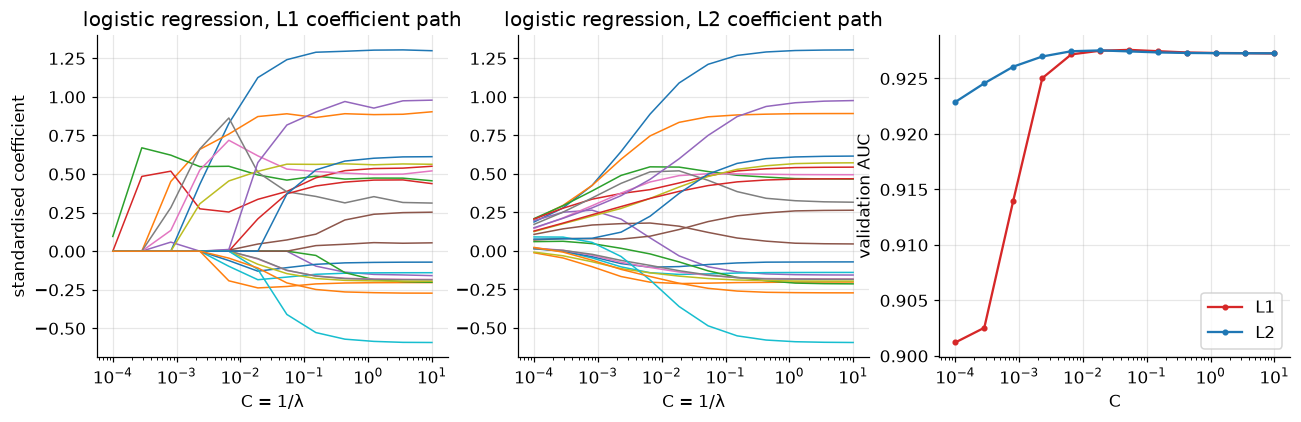

5-fold CV (L1): best C = 0.0187;  non-zero coefficients: 18 of 22


In [4]:
Cs = np.logspace(-4, 1, 12)
paths = {}
for pen in ("l1", "l2"):
    co, auc_va = [], []
    for c in Cs:
        m = LogisticRegression(penalty=pen, C=c, solver="liblinear", max_iter=500).fit(prep(Xtr), ytr)
        co.append(m.coef_[0]); auc_va.append(roc_auc_score(yva, m.decision_function(prep(Xva))))
    paths[pen] = (np.array(co), np.array(auc_va))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, pen in zip(ax[:2], ("l1", "l2")):
    a.semilogx(Cs, paths[pen][0], lw=1); a.set_xlabel("C = 1/λ"); a.set_title(f"logistic regression, {pen.upper()} coefficient path")
ax[0].set_ylabel("standardised coefficient")
for pen, c in (("l1", g.COLORS["bayes"]), ("l2", g.COLORS["freq"])): ax[2].semilogx(Cs, paths[pen][1], color=c, marker="o", ms=3, label=pen.upper())
ax[2].set_xlabel("C"); ax[2].set_ylabel("validation AUC"); ax[2].legend()
g.savefig(fig, "fig05_regularization"); plt.show()
cvm = LogisticRegressionCV(Cs=Cs, cv=5, penalty="l1", solver="liblinear", scoring="roc_auc", max_iter=500).fit(prep(Xtr), ytr)
print("5-fold CV (L1): best C = %.3g;  non-zero coefficients: %d of %d" % (cvm.C_[0], (cvm.coef_ != 0).sum(), Xtr.shape[1]))
lr = LogisticRegression(penalty="l2", C=1.0, solver="liblinear", max_iter=500).fit(prep(Xtr), ytr)

### Trees and the bias–variance trade-off

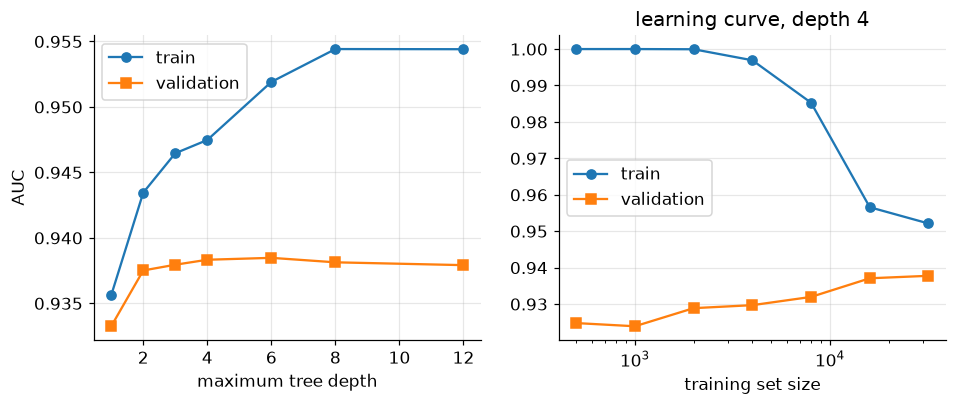

,max_depth,train_auc,val_auc,n_train,train_auc,val_auc
0,1,0.935620,0.933248,500,1.000000,0.924767
1,2,0.943452,0.937509,1000,1.000000,0.923893
2,3,0.946459,0.937947,2000,0.999948,0.928864
3,4,0.947473,0.938328,4000,0.996922,0.929686
4,6,0.951908,0.938473,8000,0.985262,0.931951
5,8,0.954417,0.938131,16000,0.956573,0.937066
6,12,0.954406,0.937915,32000,0.952112,0.937745


In [5]:
depths = [1, 2, 3, 4, 6, 8, 12]
rows = []
for d in depths:
    m = HistGradientBoostingClassifier(max_depth=d, max_iter=200, learning_rate=0.1, random_state=SEED).fit(prep(Xtr), ytr)
    rows.append(dict(max_depth=d, train_auc=roc_auc_score(ytr, m.predict_proba(prep(Xtr))[:, 1]), val_auc=roc_auc_score(yva, m.predict_proba(prep(Xva))[:, 1])))
bv = pd.DataFrame(rows)
nsz = [500, 1000, 2000, 4000, 8000, 16000, 32000]
rows = []
for n in nsz:
    ii = np.random.default_rng(1).choice(len(Xtr), n, replace=False)
    m = HistGradientBoostingClassifier(max_depth=4, max_iter=200, random_state=SEED).fit(prep(Xtr[ii]), ytr[ii])
    rows.append(dict(n=n, train_auc=roc_auc_score(ytr[ii], m.predict_proba(prep(Xtr[ii]))[:, 1]), val_auc=roc_auc_score(yva, m.predict_proba(prep(Xva))[:, 1])))
lc = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(bv.max_depth, bv.train_auc, "o-", label="train"); ax[0].plot(bv.max_depth, bv.val_auc, "s-", label="validation"); ax[0].set_xlabel("maximum tree depth"); ax[0].set_ylabel("AUC"); ax[0].legend()
ax[1].semilogx(lc.n, lc.train_auc, "o-", label="train"); ax[1].semilogx(lc.n, lc.val_auc, "s-", label="validation"); ax[1].set_xlabel("training set size"); ax[1].legend(); ax[1].set_title("learning curve, depth 4")
g.savefig(fig, "fig05_bias_variance"); plt.show()
summary["bias_variance"] = bv.to_dict("records"); summary["learning_curve"] = lc.to_dict("records")
pd.concat([bv, lc.rename(columns={"n": "n_train"})], axis=1)

ridge-logistic     validation AUC = 0.9273
random forest      validation AUC = 0.9376
gradient boosting  validation AUC = 0.9384


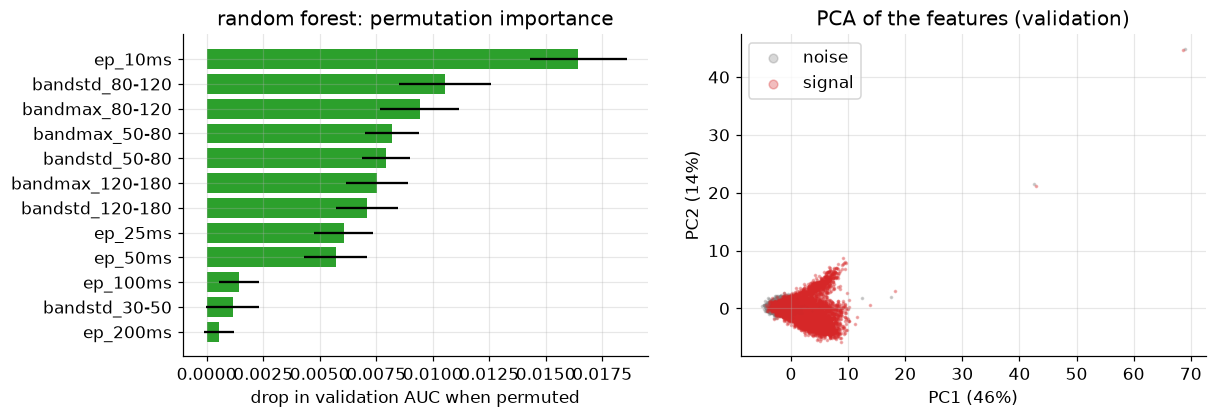

In [6]:
gb = HistGradientBoostingClassifier(max_depth=4, max_iter=300, learning_rate=0.08, random_state=SEED).fit(prep(Xtr), ytr)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(prep(Xtr), ytr)
for nm, m in (("ridge-logistic", lr), ("random forest", rf), ("gradient boosting", gb)):
    sc_ = m.decision_function(prep(Xva)) if hasattr(m, "decision_function") else m.predict_proba(prep(Xva))[:, 1]
    print(f"{nm:18s} validation AUC = {roc_auc_score(yva, sc_):.4f}")
pi = permutation_importance(rf, prep(Xva[::4]), yva[::4], n_repeats=5, scoring="roc_auc", random_state=SEED, n_jobs=-1)
o = np.argsort(-pi.importances_mean)[:12]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh([fnames[i] for i in o][::-1], pi.importances_mean[o][::-1], xerr=pi.importances_std[o][::-1], color=g.COLORS["ml"]); ax[0].set_xlabel("drop in validation AUC when permuted"); ax[0].set_title("random forest: permutation importance")
pca = PCA(n_components=6).fit(prep(Xtr)); Z = pca.transform(prep(Xva))
ax[1].scatter(Z[yva == 0, 0], Z[yva == 0, 1], s=2, alpha=.3, color=g.COLORS["grey"], label="noise"); ax[1].scatter(Z[yva == 1, 0], Z[yva == 1, 1], s=2, alpha=.3, color=g.COLORS["bayes"], label="signal")
ax[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})"); ax[1].legend(markerscale=4); ax[1].set_title("PCA of the features (validation)")
g.savefig(fig, "fig05_importance_pca"); plt.show()
summary["pca_explained"] = pca.explained_variance_ratio_.tolist(); summary["top_features"] = [fnames[i] for i in o[:6]]

## 3. Convolutional neural network

A small 1-D CNN (≈17 000 parameters) on the clipped whitened series: three Conv–BatchNorm–ReLU blocks (kernel 15, 9, 5; channels 16, 32, 64; max-pooling by 4), global max pooling (translation invariance:
the burst can sit anywhere in the window), a dense layer with dropout and a single logit. Binary cross-entropy, Adam, batch 128, early stopping on the validation loss.

CNN (mix) ready, 0 s, epochs = 14


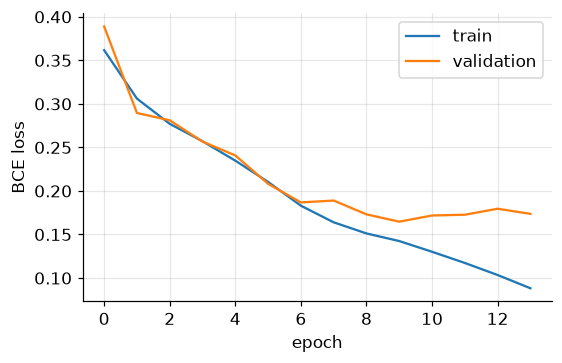

In [7]:
def build_cnn(drop=0.2, seed=0):
    tf.keras.utils.set_random_seed(seed)
    return keras.Sequential([L.Input((g.NWIN, 1)),
        L.Conv1D(16, 15, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Conv1D(32, 9, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Conv1D(64, 5, padding="same"), L.BatchNormalization(), L.ReLU(),
        L.GlobalMaxPooling1D(), L.Dense(32, activation="relu"), L.Dropout(drop), L.Dense(1)])

def train_cnn(name, sig_key, seed, epochs=18):
    fn = os.path.join(MODELS, name + ".keras")
    hist_fn = os.path.join(MODELS, name + "_hist.json")
    if os.path.exists(fn):
        return keras.models.load_model(fn), json.load(open(hist_fn))
    X = np.concatenate([clip(DS["train"]["noise"]), clip(DS["train"][sig_key])])[..., None]; y = np.r_[np.zeros(len(DS["train"]["noise"])), np.ones(len(DS["train"][sig_key]))]
    Xv = np.concatenate([clip(DS["val"]["noise"]), clip(DS["val"][sig_key])])[..., None]; yv = np.r_[np.zeros(len(DS["val"]["noise"])), np.ones(len(DS["val"][sig_key]))]
    m = build_cnn(seed=seed)
    m.compile(keras.optimizers.Adam(2e-3), keras.losses.BinaryCrossentropy(from_logits=True))
    cb = [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
          keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-4)]
    h = m.fit(X, y, validation_data=(Xv, yv), epochs=epochs, batch_size=128, callbacks=cb, verbose=0, shuffle=True)
    m.save(fn); hist = {k: [float(x) for x in v] for k, v in h.history.items() if k in ("loss", "val_loss")}
    json.dump(hist, open(hist_fn, "w")); return m, hist

t0_ = time.time()
cnn_mix, hist_mix = train_cnn("cnn_mix_s0", "mix", 0)
print("CNN (mix) ready, %.0f s, epochs = %d" % (time.time() - t0_, len(hist_mix["loss"])))
fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax.plot(hist_mix["loss"], label="train"); ax.plot(hist_mix["val_loss"], label="validation"); ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.legend()
g.savefig(fig, "fig05_cnn_training"); plt.show()

In [8]:
t0_ = time.time()
cnn_sg, _ = train_cnn("cnn_sg_s0", "sg", 0)
ens = [cnn_mix] + [train_cnn(f"cnn_mix_s{s}", "mix", s)[0] for s in range(1, 5)]
print("sg-only CNN and 5-member ensemble ready, %.0f s" % (time.time() - t0_))

sg-only CNN and 5-member ensemble ready, 1 s


## 4. Unsupervised: convolutional autoencoder

The autoencoder is trained **on real noise only** (label 0 windows of the training chunks, glitches included). A burst is something it has not learned to reconstruct, so the reconstruction error is a morphology-independent detection statistic —
the ML analogue of the excess-power statistic. Bottleneck: 32 latent values for 1024 samples.

In [9]:
def build_ae():
    tf.keras.utils.set_random_seed(0)
    inp = L.Input((g.NWIN, 1)); x = inp
    for ch in (16, 32, 64, 64): x = L.Conv1D(ch, 7, strides=2, padding="same", activation="relu")(x)         # 1024 -> 64
    x = L.Flatten()(x); z = L.Dense(32, name="latent")(x)
    x = L.Dense(64 * 64, activation="relu")(z); x = L.Reshape((64, 64))(x)
    for ch in (64, 32, 16): x = L.Conv1DTranspose(ch, 7, strides=2, padding="same", activation="relu")(x)    # 64 -> 512
    x = L.Conv1DTranspose(1, 7, strides=2, padding="same")(x)                                                # -> 1024
    return keras.Model(inp, x)
fn = os.path.join(MODELS, "ae.keras")
if os.path.exists(fn): ae = keras.models.load_model(fn); ae_hist = json.load(open(os.path.join(MODELS, "ae_hist.json")))
else:
    ae = build_ae(); ae.compile(keras.optimizers.Adam(1e-3), "mse")
    h = ae.fit(clip(DS["train"]["noise"])[..., None], clip(DS["train"]["noise"])[..., None], validation_data=(clip(DS["val"]["noise"])[..., None],) * 2,
               epochs=25, batch_size=128, verbose=0, callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])
    ae_hist = {k: [float(x) for x in v] for k, v in h.history.items()}; ae.save(fn); json.dump(ae_hist, open(os.path.join(MODELS, "ae_hist.json"), "w"))
print("autoencoder epochs:", len(ae_hist["loss"]), " final val MSE: %.4f" % ae_hist["val_loss"][-1])
def ae_scores(v, bs=1024):
    mse, loc = [], []
    for a in range(0, len(v), bs):
        x = clip(v[a:a + bs])[..., None]; r = ae.predict(x, verbose=0, batch_size=bs)
        e = ((x - r)[..., 0]) ** 2
        mse.append(e.mean(1))
        c = np.concatenate([np.zeros((len(e), 1)), np.cumsum(e, axis=1)], axis=1); w = 64          # 62 ms sliding mean of the squared error
        loc.append(((c[:, w:] - c[:, :-w]) / w)[:, 150:880].max(1))
    return np.concatenate(mse), np.concatenate(loc)
ae_score = lambda v: ae_scores(v)[0]

autoencoder epochs: 6  final val MSE: 0.8804


## 5. Everything on the same injections

Test injections: for each morphology and SNR in {3, …, 16} (500 windows each) drawn from the **test** chunks. Every statistic is evaluated on exactly the same windows:

* frequentist: matched-filter bank $\lambda_{\max}$ (notebook 03), excess power;
* feature models: ridge-logistic, gradient boosting;
* CNN trained on the mix, CNN trained on sine-Gaussians only, 5-member ensemble of the mixed CNN;
* autoencoder reconstruction error, two ways: the mean squared error of the whole window and the maximum over time of the error smoothed over 62 ms ("local max").

**All** thresholds are the 99 % quantile (FAP = 10⁻²) of the statistic on the same background: the **validation** noise windows (chunks 1 and 5; not used for training, used only for early stopping). Using one common background is what makes the comparison fair — notebook 03 used the training chunks, which include the very glitchy chunk 2 and give a more conservative threshold for the bank. The observed false-alarm probability on the **test** chunks is reported as well, and the efficiency is recomputed with thresholds set on the test noise itself (equal observed FAP).

In [10]:
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 500
banks = {i: g.SGBank(CH[i]["S1"]) for i in CH}
vte, cte = data["test"]; S1te = S1["test"]; vva, cva = data["val"], None
r = np.random.default_rng(777)
TEST = {}
t0_ = time.time()
for kind in g.MORPHS:
    for snr in SNRS:
        idx = r.choice(len(vte), NINJ, replace=False)
        ser, p, _ = g.inject(vte[idx], kind, float(snr), r, S1te[idx])
        TEST[(kind, snr)] = (ser, cte[idx])
print("injection sets: %.0f s" % (time.time() - t0_))

def logit_cnn(m, v, bs=1024): return m.predict(clip(v)[..., None], verbose=0, batch_size=bs)[:, 0]
def stat_all(v, cid):
    X = prep(features(v))
    a_mse, a_loc = ae_scores(v)
    return {"matched-filter bank": g.scan_mixed(v, cid, banks)["rho2"], "excess power": ep.stat(v),
            "ridge-logistic": lr.decision_function(X), "gradient boosting": gb.predict_proba(X)[:, 1],
            "CNN (mix)": logit_cnn(cnn_mix, v), "CNN (sg only)": logit_cnn(cnn_sg, v),
            "CNN ensemble (5)": np.mean([logit_cnn(m, v) for m in ens], axis=0), "autoencoder (MSE)": a_mse, "autoencoder (local max)": a_loc}
v_tr_all, id_tr_all = data["train"]
BKG = {"val": stat_all(data["val"][0], data["val"][1]), "test": stat_all(vte, cte)}
t0_ = time.time()
INJ = {k: stat_all(*v) for k, v in TEST.items()}
print("all statistics on the injections: %.0f s" % (time.time() - t0_))

injection sets: 1 s


all statistics on the injections: 51 s


In [11]:
STATS = list(BKG["val"].keys())
def threshold(stat, far, src="val"):
    return g.threshold_at_far(BKG[src][stat], far)
rows = []
for far in (1e-2, 1e-3):
    for s in STATS:
        thr = threshold(s, far); te = BKG["test"][s]
        k = int((te > thr).sum()); rows.append(dict(statistic=s, FAP_target=far, observed_test_FAP=k / len(te), n_alarms=k))
calib = pd.DataFrame(rows); calib.pivot(index="statistic", columns="FAP_target", values="observed_test_FAP").round(4)

FAP_target,0.001,0.010
statistic,,
CNN (mix),0.0006,0.0035
CNN (sg only),0.0021,0.0081
CNN ensemble (5),0.0010,0.0053
autoencoder (MSE),0.0014,0.0031
autoencoder (local max),0.0015,0.0060
excess power,0.0015,0.0092
gradient boosting,0.0011,0.0075
matched-filter bank,0.0015,0.0085
ridge-logistic,0.0015,0.0073


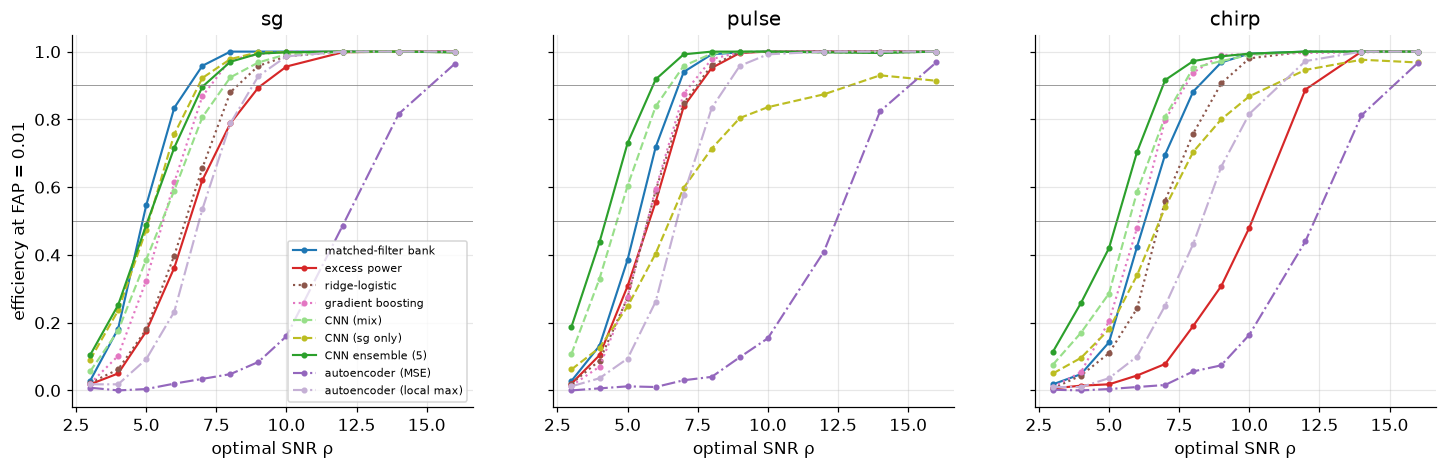

rho50 (thresholds from validation noise) | rho50 (thresholds from the test noise itself)


morphology,chirp,pulse,sg,chirp (test thr),pulse (test thr),sg (test thr)
statistic,,,,,,
CNN (mix),5.71,4.62,5.56,5.29,4.13,4.94
CNN (sg only),6.80,6.49,5.09,6.46,6.13,4.88
CNN ensemble (5),5.28,4.21,5.05,4.82,3.82,4.62
autoencoder (MSE),12.32,12.43,12.08,10.95,11.06,10.96
autoencoder (local max),8.30,6.75,6.89,7.97,6.55,6.66
excess power,10.10,5.77,6.53,10.06,5.77,6.50
gradient boosting,6.06,5.70,5.61,5.94,5.62,5.50
matched-filter bank,6.28,5.34,4.87,6.24,5.30,4.83
ridge-logistic,6.81,5.72,6.40,6.68,5.59,6.19


In [12]:
col = {"matched-filter bank": g.COLORS["freq"], "excess power": g.COLORS["bayes"], "ridge-logistic": "#8c564b", "gradient boosting": "#e377c2",
       "CNN (mix)": "#98df8a", "CNN (sg only)": "#bcbd22", "CNN ensemble (5)": g.COLORS["ml"], "autoencoder (MSE)": g.COLORS["purple"], "autoencoder (local max)": "#c5b0d5"}
ls = {"matched-filter bank": "-", "excess power": "-", "ridge-logistic": ":", "gradient boosting": ":", "CNN (mix)": "--", "CNN (sg only)": "--", "CNN ensemble (5)": "-", "autoencoder (MSE)": "-.", "autoencoder (local max)": "-."}
FAP = 1e-2
def eff(kind, s, src="val"):
    thr = threshold(s, FAP, src); e = np.array([g.efficiency(INJ[(kind, snr)][s], thr) for snr in SNRS]); return e[:, 0], e[:, 1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
rows = []
def levels(e):
    x = np.array(SNRS, float); f = lambda lv: float(np.interp(lv, np.maximum.accumulate(e), x)) if e.max() >= lv else np.nan
    return f(.5), f(.9)
for a, kind in zip(ax, g.MORPHS):
    for s in STATS:
        e, er = eff(kind, s); a.plot(SNRS, e, color=col[s], ls=ls[s], marker="o", ms=3, lw=1.4, label=s)
        et, _ = eff(kind, s, "test"); r50, r90 = levels(e); r50t, r90t = levels(et)
        rows.append(dict(morphology=kind, statistic=s, rho50=r50, rho90=r90, eff_at_rho8=float(e[SNRS.index(8)]),
                         rho50_testthr=r50t, rho90_testthr=r90t, eff_at_rho8_testthr=float(et[SNRS.index(8)])))
    a.set_title(kind); a.set_xlabel("optimal SNR ρ"); a.axhline(.9, color="grey", lw=.5); a.axhline(.5, color="grey", lw=.5)
ax[0].set_ylabel(f"efficiency at FAP = {FAP:g}"); ax[0].legend(fontsize=7.5, loc="lower right")
g.savefig(fig, "fig05_efficiency_all"); plt.show()
eff_tab = pd.DataFrame(rows)
print("rho50 (thresholds from validation noise) | rho50 (thresholds from the test noise itself)")
eff_tab.pivot(index="statistic", columns="morphology", values="rho50").round(2).join(eff_tab.pivot(index="statistic", columns="morphology", values="rho50_testthr").round(2), rsuffix=" (test thr)")

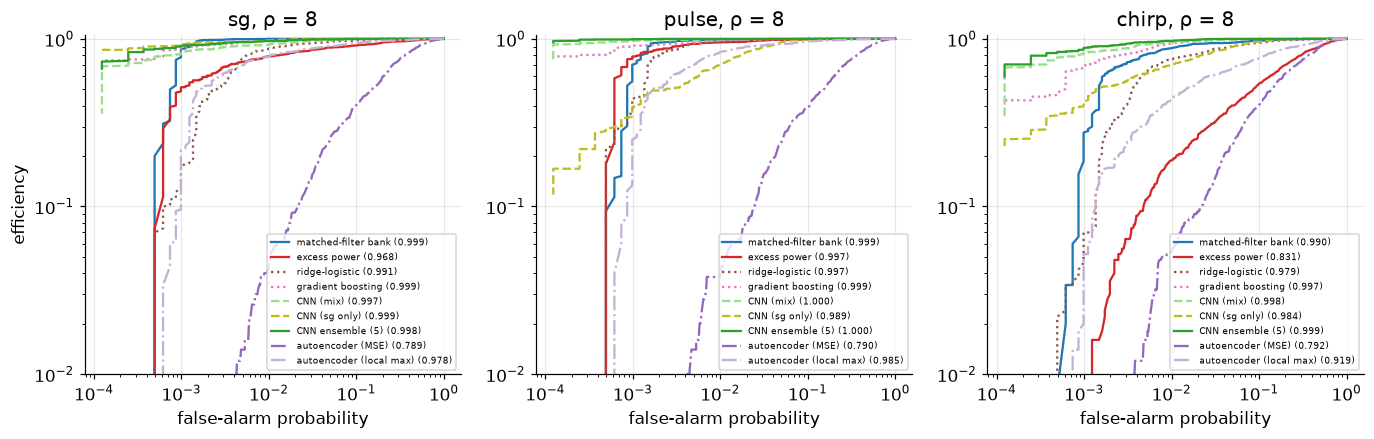

morphology,chirp,pulse,sg
statistic,,,
CNN (mix),0.998,1.000,0.997
CNN (sg only),0.984,0.989,0.999
CNN ensemble (5),0.999,1.000,0.998
autoencoder (MSE),0.792,0.790,0.789
autoencoder (local max),0.919,0.985,0.978
excess power,0.831,0.997,0.968
gradient boosting,0.997,0.999,0.999
matched-filter bank,0.990,0.999,0.999
ridge-logistic,0.979,0.997,0.991


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (kind, snr) in zip(ax, (("sg", 8), ("pulse", 8), ("chirp", 8))):
    for s in STATS:
        b = BKG["val"][s]
        far, e = g.roc(b, INJ[(kind, snr)][s]); a.loglog(far, np.maximum(e, 1e-3), color=col[s], ls=ls[s], label=f"{s} ({g.auc(b, INJ[(kind, snr)][s]):.3f})")
    a.set_title(f"{kind}, ρ = {snr}"); a.set_xlabel("false-alarm probability"); a.set_ylim(1e-2, 1.05); a.legend(fontsize=6, loc="lower right")
ax[0].set_ylabel("efficiency")
g.savefig(fig, "fig05_roc_all"); plt.show()
auc_tab = pd.DataFrame([{"morphology": k, "snr": s_, "statistic": s, "AUC": g.auc(BKG["val"][s], INJ[(k, s_)][s])}
                        for k in g.MORPHS for s_ in (6, 8, 10) for s in STATS])
auc_tab[auc_tab.snr == 8].pivot(index="statistic", columns="morphology", values="AUC").round(3)

How to read the efficiency panels (all thresholds from the same validation noise; ρ₅₀/ρ₉₀ = SNR at 50 %/90 % efficiency in the tables above):

* **In-family (sine-Gaussian).** The matched-filter bank and the 5-member CNN ensemble are close: ρ₅₀ = 4.9 and 5.1, ρ₉₀ = 6.5 and 7.1 — the bank, whose templates are of this family, is slightly better at high efficiency; with thresholds set on the test noise itself the order of ρ₅₀ is reversed (4.8 and 4.6). The feature-based models (gradient boosting 5.6, ridge 6.4) and excess power (6.5) are weaker.
* **Pulse and chirp, which the mixed networks were trained on.** The ensemble needs ρ₅₀ = 4.2 and 5.3 against 5.3 and 6.3 for the bank: about one unit of SNR better, i.e. the network has *learned* the shapes the bank only covers through its sine-Gaussian templates. Gradient boosting on 22 handcrafted features is already at the bank level.
* **A morphology the network never saw.** The CNN trained on sine-Gaussians only loses efficiency exactly where its training set stops: ρ₅₀ = 6.5 (pulse) and 6.8 (chirp), against 5.3 and 6.3 for the bank, and its efficiency at ρ = 8 falls from 0.98 (sine-Gaussian) to 0.71 and 0.70. The advantage of the supervised detector is *bought with training data*; outside the training distribution the bank, which has no training data to fail on, is the more robust.
* **Autoencoder (trained on noise only).** The reconstruction error of the whole window is just the total energy of one second of nearly white noise — there is nothing to learn from white noise — and is inefficient (ρ₅₀ ≈ 12). Looking at the *local* maximum of the error recovers the performance of the excess-power statistic (ρ₅₀ = 6.9, 6.8, 8.3) but not more: an autoencoder can beat an energy statistic only if the noise has structure it can learn, which after whitening it hardly has.
* **False alarms.** On the test chunks the observed FAP at a nominal 1 % is 0.85 % (bank), 0.92 % (excess power), 0.75 % (gradient boosting), 0.53 % (ensemble), 0.35 % (single CNN): thresholds carried from the validation epochs are conservative for the networks, and no statistic is immune to the epoch dependence of the background.

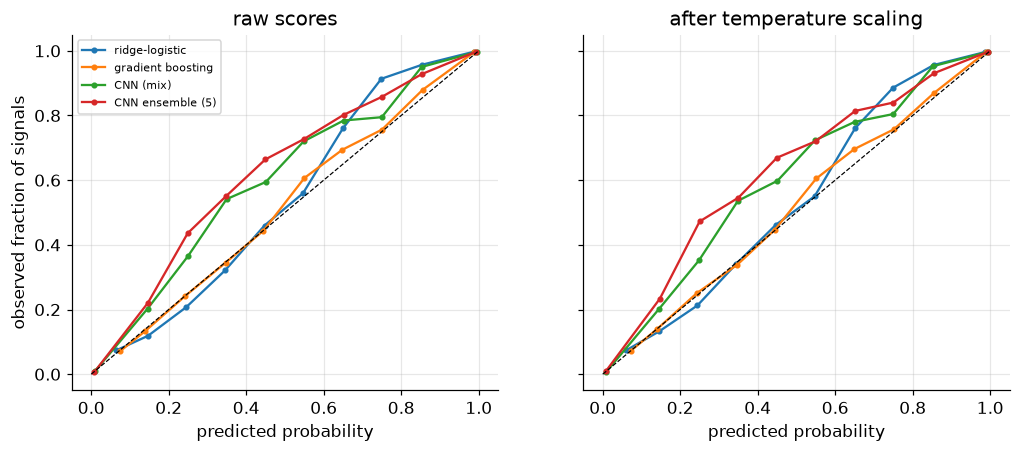

,model,temperature_scaled,T,ECE_val,ECE,brier,logloss,AUC
0,ridge-logistic,False,1.0000,0.0246,0.0266,0.0903,0.3063,0.9346
1,gradient boosting,False,1.0000,0.0080,0.0071,0.0779,0.2588,0.9450
2,CNN (mix),False,1.0000,0.0083,0.0222,0.0413,0.1280,0.9909
3,CNN ensemble (5),False,1.0000,0.0123,0.0241,0.0350,0.1097,0.9938
4,ridge-logistic,True,0.9379,0.0238,0.0207,0.0898,0.3052,0.9346
5,gradient boosting,True,0.9781,0.0099,0.0054,0.0779,0.2585,0.9450
6,CNN (mix),True,1.0220,0.0081,0.0231,0.0412,0.1281,0.9909
7,CNN ensemble (5),True,0.9481,0.0120,0.0233,0.0351,0.1097,0.9938


In [14]:
# balanced evaluation sets: noise + mixed injections (SNR 3-15), as in training
def eval_set(sp, seed):
    v, cid = data[sp]; r = np.random.default_rng(seed)
    sig, kinds, snr = make_signals(v, S1[sp], list(g.MORPHS), r)
    return np.concatenate([v, sig]), np.r_[np.zeros(len(v)), np.ones(len(v))], np.r_[np.full(len(v), np.nan), snr]
Ev = {sp: eval_set(sp, s) for sp, s in (("val", 11), ("test", 12))}
logit = {}
for sp in ("val", "test"):
    v = Ev[sp][0]; X = prep(features(v))
    logit[sp] = {"ridge-logistic": lr.decision_function(X), "gradient boosting": np.log(np.clip(gb.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6) / np.clip(gb.predict_proba(X)[:, 0], 1e-6, 1)),
                 "CNN (mix)": logit_cnn(cnn_mix, v), "CNN ensemble (5)": np.mean([logit_cnn(m, v) for m in ens], axis=0)}
sig_ = lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30)))
def ece(p, y, nb=10):
    b = np.minimum((p * nb).astype(int), nb - 1); return sum(abs(p[b == k].mean() - y[b == k].mean()) * (b == k).mean() for k in range(nb) if (b == k).any())
from scipy.optimize import minimize_scalar
temps = {}; rows = []
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for a, post in zip(ax, (False, True)):
    for nm in logit["val"]:
        T = 1.0
        if post:
            T = minimize_scalar(lambda t: log_loss(Ev["val"][1], sig_(logit["val"][nm] / t), labels=[0, 1]), bounds=(0.2, 10), method="bounded").x; temps[nm] = T
        p = sig_(logit["test"][nm] / T); y = Ev["test"][1]
        bins = np.linspace(0, 1, 11); idx = np.minimum((p * 10).astype(int), 9)
        xs = [p[idx == k].mean() for k in range(10) if (idx == k).sum() > 20]; ys = [y[idx == k].mean() for k in range(10) if (idx == k).sum() > 20]
        a.plot(xs, ys, marker="o", ms=3, label=nm)
        pv_ = sig_(logit["val"][nm] / T)
        rows.append(dict(model=nm, temperature_scaled=post, T=T, ECE_val=ece(pv_, Ev["val"][1]), ECE=ece(p, y), brier=brier_score_loss(y, p), logloss=log_loss(y, p), AUC=roc_auc_score(y, p)))
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.set_xlabel("predicted probability"); a.set_title("after temperature scaling" if post else "raw scores")
ax[0].set_ylabel("observed fraction of signals"); ax[0].legend(fontsize=7.5)
g.savefig(fig, "fig05_calibration"); plt.show()
cal_tab = pd.DataFrame(rows); summary["calibration"] = cal_tab.to_dict("records"); cal_tab.round(4)

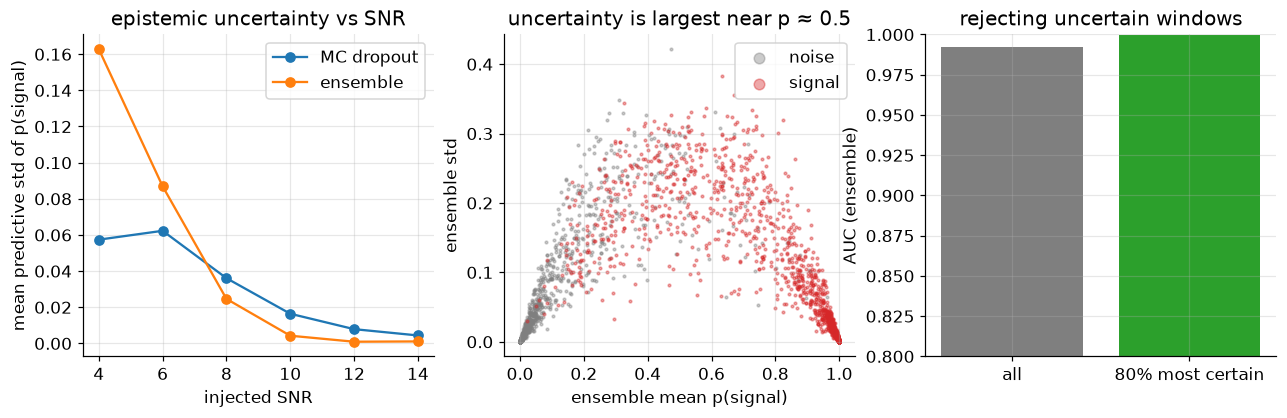

{'auc_all': 0.9924286666666668, 'auc_keep80': 0.9996989784613544, 'corr_mcd_ens': 0.3452596966462682, 'mean_std_mcd': 0.03615131601691246, 'mean_std_ens': 0.043468840420246124}


In [15]:
# MC dropout (30 stochastic passes of the single CNN) and ensemble disagreement, against SNR and on noise windows
def mc_dropout(m, v, T=30, bs=1024):
    x = clip(v)[..., None]
    return np.stack([np.concatenate([m(x[a:a + bs], training=True).numpy()[:, 0] for a in range(0, len(x), bs)]) for _ in range(T)])
vE, yE, sE = Ev["test"]
sub = np.r_[np.where(yE == 0)[0][:2000], np.where(yE == 1)[0][:3000]]
mcd = mc_dropout(cnn_mix, vE[sub]); pm = sig_(mcd)
ens_l = np.stack([logit_cnn(m, vE[sub]) for m in ens]); pe = sig_(ens_l)
unc = {"MC dropout": pm.std(0), "ensemble": pe.std(0)}
snr_bins = np.array([3, 5, 7, 9, 11, 13, 15.0]); sb = sE[sub]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for nm, u in unc.items():
    ax[0].plot(snr_bins[:-1] + 1, [u[(yE[sub] == 1) & (sb >= lo) & (sb < hi)].mean() for lo, hi in zip(snr_bins[:-1], snr_bins[1:])], marker="o", label=nm)
ax[0].set_xlabel("injected SNR"); ax[0].set_ylabel("mean predictive std of p(signal)"); ax[0].legend(); ax[0].set_title("epistemic uncertainty vs SNR")
mean_p = pe.mean(0)
ax[1].scatter(mean_p[yE[sub] == 0], unc["ensemble"][yE[sub] == 0], s=3, alpha=.4, color=g.COLORS["grey"], label="noise"); ax[1].scatter(mean_p[yE[sub] == 1], unc["ensemble"][yE[sub] == 1], s=3, alpha=.4, color=g.COLORS["bayes"], label="signal")
ax[1].set_xlabel("ensemble mean p(signal)"); ax[1].set_ylabel("ensemble std"); ax[1].legend(markerscale=4); ax[1].set_title("uncertainty is largest near p ≈ 0.5")
# selective prediction: keep the 80% most certain test windows
keep = unc["ensemble"] < np.quantile(unc["ensemble"], .8)
auc_all = roc_auc_score(yE[sub], mean_p); auc_keep = roc_auc_score(yE[sub][keep], mean_p[keep])
ax[2].bar(["all", "80% most certain"], [auc_all, auc_keep], color=[g.COLORS["grey"], g.COLORS["ml"]]); ax[2].set_ylim(0.8, 1); ax[2].set_ylabel("AUC (ensemble)"); ax[2].set_title("rejecting uncertain windows")
g.savefig(fig, "fig05_uncertainty"); plt.show()
summary["uncertainty"] = dict(auc_all=float(auc_all), auc_keep80=float(auc_keep), corr_mcd_ens=float(np.corrcoef(unc["MC dropout"], unc["ensemble"])[0, 1]),
                              mean_std_mcd=float(unc["MC dropout"].mean()), mean_std_ens=float(unc["ensemble"].mean()))
print(summary["uncertainty"])

What the figures say.

1. **Calibration.** All models are close to calibrated: ECE is 0.7 % for gradient boosting, 2.2–2.4 % for the CNNs and 2.7 % for the ridge model on the test set. The CNNs are slightly *under*-confident at intermediate scores (the observed signal fraction exceeds the prediction by up to ≈0.15 between 0.1 and 0.7).
2. **Temperature scaling does not help here** (fitted T = 0.94–1.02, ECE changes by ≤ 0.002): the miscalibration is not of the temperature type. For the CNNs the ECE is 0.8–1.2 % on the validation epochs they were tuned on and 2.2–2.4 % on the test epochs, so most of it is an **epoch shift**, not over-confidence.
3. **Ensemble against single network.** The ensemble is better in every proper score (Brier 0.0350 against 0.0413, log-loss 0.110 against 0.128, AUC 0.9938 against 0.9909).
4. **Epistemic uncertainty.** The spread of the ensemble falls with the SNR (mean std 0.16 at ρ ≈ 4, ≈ 0.001 at ρ ≥ 12) and is largest at p ≈ 0.5; MC dropout shows the same trend but is only moderately correlated with the ensemble (0.35): they measure different things (the spread over dropout masks of one network, against the disagreement of independently trained networks).
5. **Selective prediction.** Rejecting the 20 % most uncertain windows raises the AUC from 0.9924 to 0.9997: a model that knows when it does not know is more useful in a search than one that is only slightly more accurate.

## 7. Cross-epoch generalisation

Validation and test chunks come from different epochs of the run. The AUC on the two sets (below, balanced noise/mixed-injection sets) tells whether the models over-fit the noise of the training epochs: it is *higher* on the test epochs for every model (CNN ensemble 0.988 → 0.994, single CNN 0.983 → 0.991, gradient boosting 0.937 → 0.945, ridge 0.926 → 0.935) because the test chunks are cleaner than the validation ones; there is no sign of over-fitting to the training epochs.

In [16]:
rows = []
for nm in logit["val"]:
    rows.append(dict(model=nm, AUC_val=roc_auc_score(Ev["val"][1], logit["val"][nm]), AUC_test=roc_auc_score(Ev["test"][1], logit["test"][nm])))
gen = pd.DataFrame(rows)
print(gen.round(4))
summary["generalisation"] = gen.to_dict("records")

               model  AUC_val  AUC_test
0     ridge-logistic   0.9256    0.9346
1  gradient boosting   0.9366    0.9450
2          CNN (mix)   0.9830    0.9909
3   CNN ensemble (5)   0.9884    0.9938


## Summary

In [17]:
summary.update(efficiency_table=eff_tab.to_dict("records"), auc_table=auc_tab.to_dict("records"), calibration_far=calib.to_dict("records"),
               eff_curves={f"{k}/{s}": dict(snr=SNRS, eff=eff(k, s)[0].tolist(), eff_testthr=eff(k, s, "test")[0].tolist()) for k in g.MORPHS for s in STATS},
               cnn=dict(epochs=len(hist_mix["loss"]), params=int(cnn_mix.count_params()), ae_params=int(ae.count_params())),
               lr_cv=dict(best_C=float(cvm.C_[0]), nonzero=int((cvm.coef_ != 0).sum())), n_features=len(fnames))
g.save_json(summary, "05_summary.json")
print("saved:", list(summary))

saved: ['bias_variance', 'learning_curve', 'pca_explained', 'top_features', 'calibration', 'uncertainty', 'generalisation', 'efficiency_table', 'auc_table', 'calibration_far', 'eff_curves', 'cnn', 'lr_cv', 'n_features']


## Output and next step

* `results/05_summary.json`, `figures/fig05_*`; trained models in `cache/models/` (not tracked: regenerated in ≈20–30 min by re-running).

This closes the analysis: the report in `Docs/report/` collects the three approaches and compares them on the same data.